In [1]:
import csv
from pathlib import Path
import pandas as pd

PFAD = Path("data/raw/2025_Velo_Fuss_Count.csv")

# Trennzeichen automatisch erkennen (Komma oder Semikolon)
with open(PFAD, encoding="utf-8", errors="replace") as f:
    trennzeichen = csv.Sniffer().sniff(f.readline()).delimiter

df = pd.read_csv(PFAD, sep=trennzeichen, encoding_errors="replace", low_memory=False)
print("Trennzeichen:", repr(trennzeichen))
print("Zeilen, Spalten:", df.shape)

Trennzeichen: ';'
Zeilen, Spalten: (596376, 21)


In [2]:
df.head()

,SiteCode,SiteName,DirectionName,LaneCode,LaneName,Date,TimeFrom,TimeTo,ValuesApproved,ValuesEdited,...,Total,DateTimeFrom,DateTimeTo,Year,Month,Day,Weekday,HourFrom,DayOfYear,Zst_id
0,350,350 Dreirosenbrücke,1 nach Kleinbasel,7.0,Spur 7,01.01.2025,00:00,01:00,1,0,...,40,2025-01-01 00:00:00,2025-01-01 01:00:00,2025,1,1,2,0,1,350
1,350,350 Dreirosenbrücke,1 nach Kleinbasel,7.0,Spur 7,01.01.2025,01:00,02:00,1,0,...,30,2025-01-01 01:00:00,2025-01-01 02:00:00,2025,1,1,2,1,1,350
2,350,350 Dreirosenbrücke,1 nach Kleinbasel,7.0,Spur 7,01.01.2025,02:00,03:00,1,0,...,22,2025-01-01 02:00:00,2025-01-01 03:00:00,2025,1,1,2,2,1,350
3,350,350 Dreirosenbrücke,1 nach Kleinbasel,7.0,Spur 7,01.01.2025,03:00,04:00,1,0,...,12,2025-01-01 03:00:00,2025-01-01 04:00:00,2025,1,1,2,3,1,350
4,350,350 Dreirosenbrücke,1 nach Kleinbasel,7.0,Spur 7,01.01.2025,04:00,05:00,1,0,...,20,2025-01-01 04:00:00,2025-01-01 05:00:00,2025,1,1,2,4,1,350


In [4]:
df.dtypes

SiteCode            int64
SiteName              str
DirectionName         str
LaneCode          float64
LaneName              str
Date                  str
TimeFrom              str
TimeTo                str
ValuesApproved      int64
ValuesEdited        int64
TrafficType           str
Total               int64
DateTimeFrom          str
DateTimeTo            str
Year                int64
Month               int64
Day                 int64
Weekday             int64
HourFrom            int64
DayOfYear           int64
Zst_id              int64
dtype: object

In [6]:
for spalte in df.columns:
    anzahl = df[spalte].nunique()
    ist_text = not pd.api.types.is_numeric_dtype(df[spalte])
    if ist_text and anzahl <= 30:
        print(f"--- {spalte} ({anzahl} Werte) ---")
        print(df[spalte].value_counts().head(10), "\n")

--- LaneName (10 Werte) ---
LaneName
S1             140904
Spur 1         132936
Spur 2         124176
S2              78096
Spur 8          48144
Spur 7          45936
Spur 2 Velo      8760
Spur 1 Velo      5136
IN               2496
OUT              2496
Name: count, dtype: int64 

--- TimeFrom (24 Werte) ---
TimeFrom
00:00    24849
01:00    24849
02:00    24849
03:00    24849
04:00    24849
05:00    24849
06:00    24849
07:00    24849
08:00    24849
09:00    24849
Name: count, dtype: int64 

--- TimeTo (24 Werte) ---
TimeTo
01:00    24849
02:00    24849
03:00    24849
04:00    24849
05:00    24849
06:00    24849
07:00    24849
08:00    24849
09:00    24849
10:00    24849
Name: count, dtype: int64 

--- TrafficType (2 Werte) ---
TrafficType
Velo          372384
Fussgänger    223992
Name: count, dtype: int64 



In [7]:
velo = df[df["TrafficType"] == "Velo"].copy()
datumsteile = velo[["Year", "Month", "Day"]].rename(columns=str.lower)
velo["Datum"] = pd.to_datetime(datumsteile)

print("Velo-Zeilen:", len(velo))
print("Zählstellen:", velo["Zst_id"].nunique())

Velo-Zeilen: 372384
Zählstellen: 23


In [8]:
tage_pro_stelle = velo.groupby("Zst_id")["Datum"].nunique().sort_values(ascending=False)
tage_pro_stelle

Zst_id
354    365
403    365
405    365
901    365
660    365
904    365
903    365
913    365
914    365
906    365
907    365
908    365
909    365
910    365
911    365
952    365
917    365
919    365
915    337
659    334
918    306
350    212
916    151
Name: Datum, dtype: int64

In [9]:
gute_stellen = tage_pro_stelle[tage_pro_stelle >= 360].index
velo_gut = velo[velo["Zst_id"].isin(gute_stellen)]

pro_tag = velo_gut.groupby("Datum")["Total"].sum().reset_index(name="velos")

print("Zählstellen mit ganzem Jahr:", len(gute_stellen))
pro_tag.head(10)

Zählstellen mit ganzem Jahr: 18


,Datum,velos
0,2025-01-01,11104
1,2025-01-02,15707
2,2025-01-03,17789
3,2025-01-04,14240
4,2025-01-05,11561
5,2025-01-06,34911
6,2025-01-07,40328
7,2025-01-08,30673
8,2025-01-09,37506
9,2025-01-10,35460


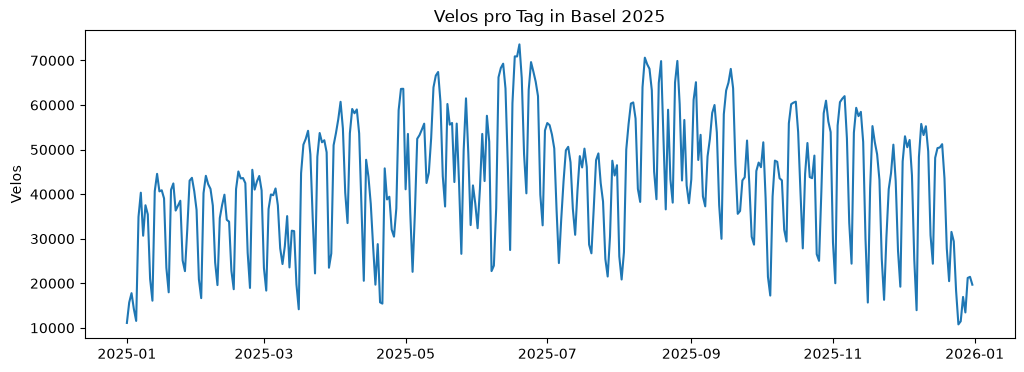

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))
plt.plot(pro_tag["Datum"], pro_tag["velos"])
plt.title("Velos pro Tag in Basel 2025")
plt.ylabel("Velos")
plt.show()